<a href="https://colab.research.google.com/github/faithwanjiku/ecommerce-data-analysis/blob/main/Eccomerce_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Customers: (99441, 5)
Products: (32951, 9)
Orders: (99441, 8)
Order Items: (112650, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 no

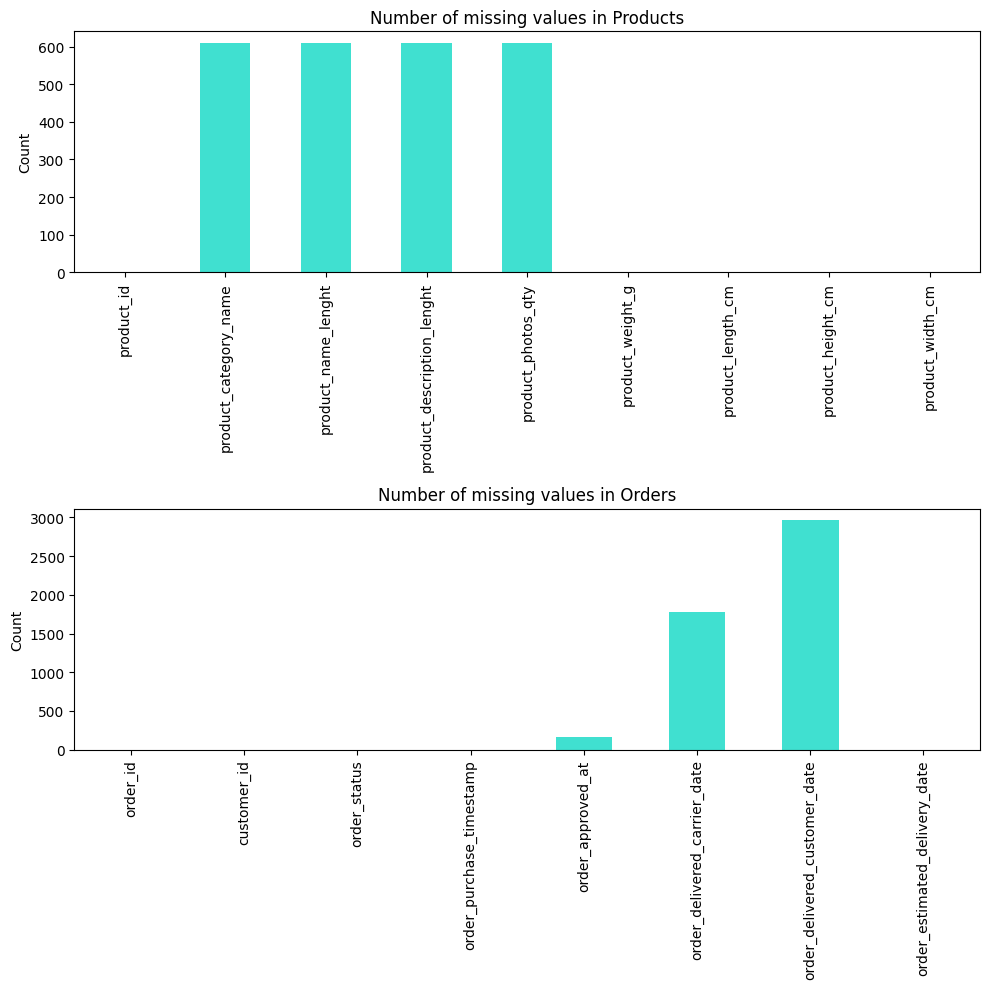

Duplicate rows in Customers: 0
Duplicate rows in Products: 0
Duplicate rows in Orders: 0
Duplicate rows in Order Items: 0
product_category_name
cama_mesa_banho                      3029
esporte_lazer                        2867
moveis_decoracao                     2657
beleza_saude                         2444
utilidades_domesticas                2335
automotivo                           1900
informatica_acessorios               1639
brinquedos                           1411
relogios_presentes                   1329
telefonia                            1134
bebes                                 919
perfumaria                            868
papelaria                             849
fashion_bolsas_e_acessorios           849
cool_stuff                            789
ferramentas_jardim                    753
pet_shop                              719
NaN                                   610
eletronicos                           517
construcao_ferramentas_construcao     400
eletrodomesticos

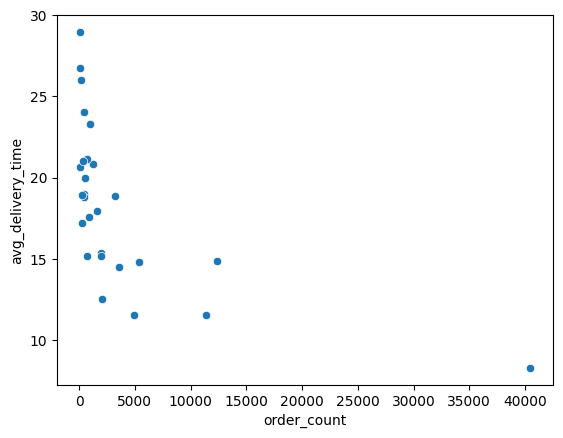

In [6]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load data
customers = pd.read_csv('https://raw.githubusercontent.com/faithwanjiku/ecommerce-data-analysis/refs/heads/main/data/olist_customers_dataset.csv')
products = pd.read_csv('https://raw.githubusercontent.com/faithwanjiku/ecommerce-data-analysis/refs/heads/main/data/olist_products_dataset.csv')
orders = pd.read_csv('https://raw.githubusercontent.com/faithwanjiku/ecommerce-data-analysis/refs/heads/main/data/olist_orders_dataset.csv')
order_items = pd.read_csv('https://raw.githubusercontent.com/faithwanjiku/ecommerce-data-analysis/refs/heads/main/data/olist_order_items_dataset.csv')

# Data Inspection
# displays first ten rows of each datasets
customers.head(10)
products.head(10)
orders.head(10)
order_items.head(10)

# check the number of rows and columns we have per dataset
print('Customers:', customers.shape)
print('Products:', products.shape)
print('Orders:', orders.shape)
print('Order Items:', order_items.shape)

#check more information about the datasets
customers.info()
products.info()
orders.info()
order_items.info()

#check missing values in our datasets
print(customers.isnull().sum())
print(products.isnull().sum())
print(orders.isnull().sum())
print(order_items.isnull().sum())

# Visualizing missing values for products and orders dataset to identify columns that needs cleaning
fig, ax=plt.subplots(2,1,figsize=(10,10))
products.isnull().sum().plot(kind ='bar', ax=ax[0], color='Turquoise')
ax[0].set_ylabel('Count')
ax[0].set_title('Number of missing values in Products')

orders.isnull().sum().plot(kind ='bar', ax=ax[1], color='Turquoise')
ax[1].set_ylabel('Count')
ax[1].set_title('Number of missing values in Orders')

plt.tight_layout()
plt.show()

#Check for duplicate values in each dataset
print(f"Duplicate rows in Customers: {customers.duplicated().sum()}")
print(f"Duplicate rows in Products: {products.duplicated().sum()}")
print(f"Duplicate rows in Orders: {orders.duplicated().sum()}")
print(f"Duplicate rows in Order Items: {order_items.duplicated().sum()}")

#Data Cleaning
# check for NaN in 'product_category_name column
print(products['product_category_name'].value_counts(dropna=False).head(30))

# Remove rows with missing values in product_category_name
products_clean=products.dropna(subset=['product_category_name'])
print(products_clean.isnull().sum())
print(products_clean.shape)

# investigating orders dataset missing values
print(orders['order_status'].value_counts())

print(orders.groupby('order_status')['order_delivered_customer_date'].apply(lambda x: x.isna().sum()))
# Most missing values in the approval and delivery date columns
# belong to orders that were not delivered (such as invoiced,
# created, or cancelled orders). These missing values are expected,
# so i will keep these rows.

#changing data types for orders date columns from Object to Datetime64
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date']
orders[date_columns] = orders[date_columns].apply(pd.to_datetime)
print(orders.dtypes)

# Performing EDA and feature engineering where necessary while answering some business questions.

# Total orders
total_orders = orders['order_id'].count()
print(total_orders)

#Total sales
total_sales = order_items['price'].sum()
print(total_sales)

# Which is the most sold product categories.
# we merge order_items and products using a left join
order_items_products = order_items.merge(products_clean, on='product_id', how='left')
print(order_items_products.shape)
order_items_products.head(10)
#check for null in the new product_category name
print(order_items_products['product_category_name'].value_counts(dropna=False))

# After merging the order_items and product_clean i noticed that product_category_name
# has some new null values. To deal with them I used fillna() and assign them the name 'unkown_product'
order_items_products['product_category_name'] = order_items_products['product_category_name'].fillna('unknown_products')

most_sold_product_category= order_items_products['product_category_name'].value_counts()
print(most_sold_product_category.head(10))


#what is the average delivery time
#To calculate the delivery time, deduct order_purchase date from order_delivered date
delivered_orders = orders[orders['order_status'] == 'delivered'].copy()
delivered_orders = delivered_orders.dropna(subset=['order_delivered_customer_date']).copy()
delivered_orders['delivery_duration'] = (delivered_orders['order_delivered_customer_date'] - delivered_orders['order_purchase_timestamp']).dt.days

avg_delivery_time = delivered_orders['delivery_duration'].mean().round(2)
print(avg_delivery_time)

delivered_orders['delivery_duration'].describe()

#Which month has the highest numbers of orders
#extract month from timestamp
orders['order_month'] = orders['order_purchase_timestamp'].dt.month_name()
highest_order_month = orders['order_month'].value_counts()
print(highest_order_month.sort_values(ascending=False))

#extract year from timestamp
orders['order_year'] = orders['order_purchase_timestamp'].dt.year

#which states has the most orders?
# We merge orders with customer table using a left join
orders_customers = orders.merge(customers, on='customer_id', how='left')
print(orders_customers.shape)
orders_customers.head(10)

orders_in_states = orders_customers['customer_state'].value_counts()
print(orders_in_states.head(10))

#which product category generates most revenue.
revenue_sales = order_items_products.groupby('product_category_name')['price'].sum()
print(revenue_sales.sort_values(ascending=False))

#check revenue generated by the 'unknown products'
unknown_products_rev = revenue_sales['unknown_products']

# its percentage from the total_sales
pect_unknown_products_rev = (unknown_products_rev/total_sales) * 100
print(pect_unknown_products_rev)

# Calculate the percentage of on timely deliveries vs late deliveries
#lets calculate deliver delays
delivered_orders['delivery_delay'] = (delivered_orders['order_delivered_customer_date'] - delivered_orders['order_estimated_delivery_date']).dt.days

delivered_orders['delivery_status'] = delivered_orders['delivery_delay'].apply(lambda x: 'Late' if x > 0 else 'On Time')

pect_time_delivery = delivered_orders['delivery_status'].value_counts(normalize=True).round(2)* 100

print(pect_time_delivery)

#Which states experience the longest average deliverly time- average deliverytime for each state.
delivered_orders_customers = delivered_orders.merge(customers, on='customer_id',how='left')
state_longest_delivery_time = delivered_orders_customers.groupby('customer_state')['delivery_duration'].mean(). round()

print(state_longest_delivery_time.sort_values(ascending=False).head(10))

#calculate correlation between order count and average delivery time
group_data = delivered_orders_customers.groupby('customer_state').agg(order_count= ('order_id', 'nunique'), avg_delivery_time = ('delivery_duration', 'mean'))
correlation = group_data['order_count'].corr(group_data['avg_delivery_time'])
print(correlation)

#visualizing correlation using a scatterplot
sns.scatterplot(data=group_data, x='order_count', y='avg_delivery_time')
plt.show()


#KEY FINDINGS
#Total orders are 99441
#Total sales is 13,591,643 Euros
#The most sold product was cama_mesa_banho(bed, table and bath)
#The state with most orders was SP
#The average delivery time was 12 days
#The month with the highest number of orders was August
#The product category generating the highest sales is beleza_saude(beauty_health)
#The state experiencing the longest delivery time is RR
#93% of the orders are delivered on time and 7% are late
#there is a negative correlation of -0.5 between orders count and avg delivery time across states


#create an excel file with three sheets(converting the DataFrames to Excel files)
with pd.ExcelWriter('ecommerce_powerbi_data.xlsx') as writer:
    orders_customers.to_excel(writer, sheet_name='Orders', index=False)
    order_items_products.to_excel(writer, sheet_name='Sales', index=False)
    delivered_orders_customers.to_excel(writer, sheet_name='Delivery', index=False)

In [3]:
ustomers = pd.read_csv('https://raw.githubusercontent.com/faithwanjiku/ecommerce-data-analysis/refs/heads/main/data/olist_customers_dataset.csv')
print(customers.head())

                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  
